<a href="https://colab.research.google.com/github/AnishIdhayan-1412/DL-CBL-PS15/blob/main/RA2311026050078_PS15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PS-15: Skin Lesion Classification (HAM10000)
**Name / Register No / Section:** ______  
**Challenge:** class imbalance (nevi ≈ 67%) + multiple images per lesion → **split by `lesion_id`**, judge by **macro F1**.  
Run on Colab GPU (Runtime → T4). Total run time ≈ 20–30 min.

## 0. Setup and reproducibility

In [2]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/ham10000
!unzip -q "/content/drive/MyDrive/ham10000/HAM10000_images_part_1.zip" -d /content/ham10000
!unzip -q "/content/drive/MyDrive/ham10000/HAM10000_images_part_2.zip" -d /content/ham10000
!cp "/content/drive/MyDrive/ham10000/HAM10000_metadata.csv" /content/ham10000/
!find /content/ham10000 -name "*.jpg" | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/ham10000/ISIC_0024306.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: replace /content/ham10000/ISIC_0029306.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/ham10000/ISIC_0029307.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/ham10000/ISIC_0029308.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 10015


In [3]:
import os, glob, random, time, numpy as np, pandas as pd, torch, torch.nn as nn, sklearn, torchvision
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from torchvision import transforms as T, models
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, balanced_accuracy_score, accuracy_score)

SEED = 42
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| sklearn', sklearn.__version__, '| device', device)

DATA_DIR = '/content/ham10000'   # <-- CHANGE: folder containing HAM10000_metadata.csv and the image folders (part_1, part_2)
IMG = 224; BS = 64; EPOCHS = 12; PATIENCE = 4

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | sklearn 1.6.1 | device cuda


## 1. Load data and EDA (class counts + samples)

10015 images | 7470 unique lesions | 1956 lesions have >1 image
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


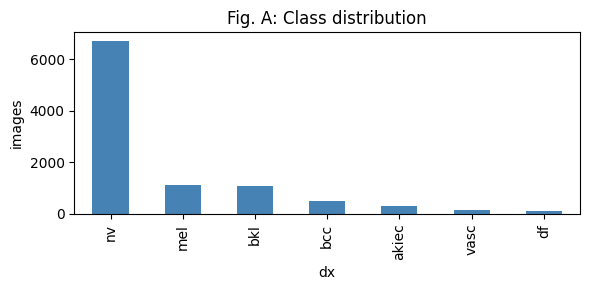

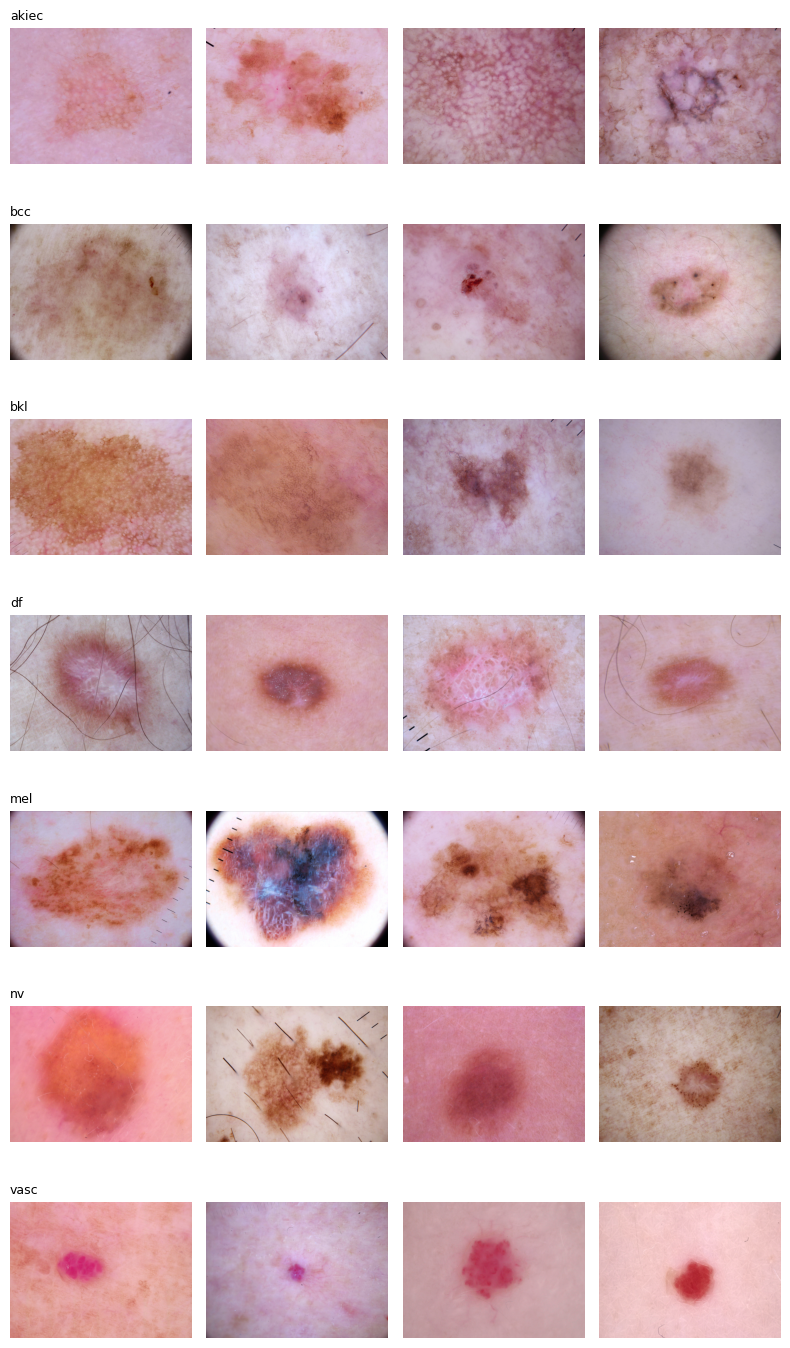

In [4]:
meta = pd.read_csv(f'{DATA_DIR}/HAM10000_metadata.csv')
paths = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob(f'{DATA_DIR}/**/*.jpg', recursive=True)}
meta['path'] = meta.image_id.map(paths)
assert meta.path.notna().all(), 'Some images not found - check DATA_DIR'
classes = sorted(meta.dx.unique()); c2i = {c:i for i,c in enumerate(classes)}
meta['label'] = meta.dx.map(c2i)
meta = meta.reset_index(drop=True)
print(len(meta), 'images |', meta.lesion_id.nunique(), 'unique lesions |', (meta.groupby('lesion_id').size()>1).sum(), 'lesions have >1 image')

counts = meta.dx.value_counts()
print(counts)
plt.figure(figsize=(6,3)); counts.plot.bar(color='steelblue'); plt.ylabel('images'); plt.title('Fig. A: Class distribution'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(len(classes), 4, figsize=(8, 2*len(classes)))
for r, c in enumerate(classes):
    for k, (_, row) in enumerate(meta[meta.dx==c].sample(4, random_state=SEED).iterrows()):
        ax[r,k].imshow(Image.open(row.path)); ax[r,k].axis('off')
    ax[r,0].set_title(c, loc='left', fontsize=9)
plt.tight_layout(); plt.show()

## 2. Split by lesion_id (no lesion appears in more than one split) — 70/15/15, stratified

In [5]:
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(meta, meta.label, groups=meta.lesion_id)]
test_idx, val_idx = folds[0], folds[1]
train_idx = np.concatenate(folds[2:])
meta['split'] = 'train'; meta.loc[val_idx,'split']='val'; meta.loc[test_idx,'split']='test'

# leakage check
L = {s:set(meta[meta.split==s].lesion_id) for s in ['train','val','test']}
assert not (L['train']&L['val']) and not (L['train']&L['test']) and not (L['val']&L['test'])
print('No lesion overlap between splits.')
print(pd.crosstab(meta.dx, meta.split)[['train','val','test']])
meta.to_csv('split_seed42.csv', index=False)   # saved split for reproducibility

No lesion overlap between splits.
split  train   val  test
dx                      
akiec    238    48    41
bcc      306   123    85
bkl      766   149   184
df        66    22    27
mel      730   196   187
nv      4485  1116  1104
vasc     100    20    22


## 3. Pre-load images at 224×224 (fast training) and build datasets

In [6]:
def load(p): return Image.open(p).convert('RGB').resize((IMG, IMG), Image.BILINEAR)
with ThreadPoolExecutor(8) as ex: IMGS = list(ex.map(load, meta.path))

mean, std = [0.485,0.456,0.406], [0.229,0.224,0.225]
train_tf = T.Compose([T.RandomResizedCrop(IMG, scale=(0.7,1.0)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.RandomRotation(20), T.ColorJitter(0.2,0.2,0.2,0.02), T.ToTensor(), T.Normalize(mean,std)])
eval_tf  = T.Compose([T.ToTensor(), T.Normalize(mean,std)])   # no augmentation on val/test

class DS(torch.utils.data.Dataset):
    def __init__(s, idx, tf): s.idx, s.tf = np.array(idx), tf
    def __len__(s): return len(s.idx)
    def __getitem__(s, i):
        j = s.idx[i]; return s.tf(IMGS[j]), int(meta.label[j])

mk = lambda idx, tf, sh: torch.utils.data.DataLoader(DS(idx, tf), batch_size=BS, shuffle=sh, num_workers=2, pin_memory=True)
dl_tr, dl_va, dl_te = mk(train_idx, train_tf, True), mk(val_idx, eval_tf, False), mk(test_idx, eval_tf, False)

## 4. Model, imbalance handling (class-weighted loss) and training loop
Two ImageNet backbones are compared on the **validation** set; only the winner touches the test set.

In [7]:
def build(name):
    if name == 'resnet18':
        m = models.resnet18(weights='IMAGENET1K_V1'); m.fc = nn.Linear(m.fc.in_features, len(classes))
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights='IMAGENET1K_V1'); m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(classes))
    return m.to(device)

cnt = np.bincount(meta.label[train_idx], minlength=len(classes))
cw = torch.tensor((cnt.sum()/(len(classes)*cnt))**0.5, dtype=torch.float32, device=device)  # sqrt-inverse-frequency weights
print('class weights:', dict(zip(classes, cw.cpu().numpy().round(2))))
crit = nn.CrossEntropyLoss(weight=cw)

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); P, Y, L, n = [], [], 0, 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device, enabled=device=='cuda'):
            o = model(x)
        L += crit(o.float(), y).item()*len(y); n += len(y)
        P.append(o.float().softmax(1).cpu()); Y.append(y.cpu())
    P, Y = torch.cat(P).numpy(), torch.cat(Y).numpy()
    return L/n, P, Y

def train(name):
    seed_all(SEED); model = build(name)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    scaler = torch.cuda.amp.GradScaler(enabled=device=='cuda')
    H = dict(tr_loss=[], va_loss=[], tr_acc=[], va_acc=[], va_f1=[]); best, bad, t0 = -1, 0, time.time()
    for ep in range(EPOCHS):
        model.train(); tl, tc, n = 0, 0, 0
        for x, y in dl_tr:
            x, y = x.to(device), y.to(device); opt.zero_grad()
            with torch.autocast(device, enabled=device=='cuda'):
                o = model(x); loss = crit(o.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item()*len(y); tc += (o.argmax(1)==y).sum().item(); n += len(y)
        sched.step()
        vl, P, Y = evaluate(model, dl_va); pr = P.argmax(1)
        f1 = f1_score(Y, pr, average='macro')
        H['tr_loss'].append(tl/n); H['tr_acc'].append(tc/n); H['va_loss'].append(vl); H['va_acc'].append((pr==Y).mean()); H['va_f1'].append(f1)
        print(f'{name} ep{ep+1:02d} tr_loss {tl/n:.3f} tr_acc {tc/n:.3f} | va_loss {vl:.3f} va_acc {(pr==Y).mean():.3f} va_macroF1 {f1:.3f}')
        if f1 > best: best, bad = f1, 0; torch.save(model.state_dict(), f'{name}_best.pt')
        else:
            bad += 1
            if bad >= PATIENCE: print('early stop'); break
    return H, best, time.time()-t0

results = {}
for name in ['resnet18', 'efficientnet_b0']:
    results[name] = train(name)
print(pd.DataFrame({k:{'best val macro F1':round(v[1],3), 'train time (s)':round(v[2])} for k,v in results.items()}).T)

class weights: {'akiec': np.float32(2.0), 'bcc': np.float32(1.77), 'bkl': np.float32(1.12), 'df': np.float32(3.81), 'mel': np.float32(1.14), 'nv': np.float32(0.46), 'vasc': np.float32(3.09)}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 181MB/s]
/tmp/ipykernel_2851/2238985767.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device=='cuda')


resnet18 ep01 tr_loss 1.038 tr_acc 0.696 | va_loss 0.748 va_acc 0.732 va_macroF1 0.553
resnet18 ep02 tr_loss 0.808 tr_acc 0.757 | va_loss 0.775 va_acc 0.728 va_macroF1 0.548
resnet18 ep03 tr_loss 0.691 tr_acc 0.790 | va_loss 0.716 va_acc 0.734 va_macroF1 0.564
resnet18 ep04 tr_loss 0.635 tr_acc 0.807 | va_loss 0.637 va_acc 0.793 va_macroF1 0.590
resnet18 ep05 tr_loss 0.542 tr_acc 0.819 | va_loss 0.654 va_acc 0.788 va_macroF1 0.568
resnet18 ep06 tr_loss 0.482 tr_acc 0.846 | va_loss 0.544 va_acc 0.806 va_macroF1 0.659
resnet18 ep07 tr_loss 0.435 tr_acc 0.855 | va_loss 0.582 va_acc 0.792 va_macroF1 0.618
resnet18 ep08 tr_loss 0.358 tr_acc 0.880 | va_loss 0.606 va_acc 0.781 va_macroF1 0.644
resnet18 ep09 tr_loss 0.319 tr_acc 0.889 | va_loss 0.601 va_acc 0.786 va_macroF1 0.652
resnet18 ep10 tr_loss 0.279 tr_acc 0.905 | va_loss 0.587 va_acc 0.806 va_macroF1 0.677
resnet18 ep11 tr_loss 0.235 tr_acc 0.923 | va_loss 0.572 va_acc 0.821 va_macroF1 0.697
resnet18 ep12 tr_loss 0.223 tr_acc 0.922 | 

100%|██████████| 20.5M/20.5M [00:00<00:00, 167MB/s]
/tmp/ipykernel_2851/2238985767.py:29: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device=='cuda')


efficientnet_b0 ep01 tr_loss 1.113 tr_acc 0.709 | va_loss 0.564 va_acc 0.800 va_macroF1 0.607
efficientnet_b0 ep02 tr_loss 0.705 tr_acc 0.789 | va_loss 0.534 va_acc 0.816 va_macroF1 0.633
efficientnet_b0 ep03 tr_loss 0.586 tr_acc 0.818 | va_loss 0.569 va_acc 0.796 va_macroF1 0.636
efficientnet_b0 ep04 tr_loss 0.486 tr_acc 0.841 | va_loss 0.506 va_acc 0.826 va_macroF1 0.671
efficientnet_b0 ep05 tr_loss 0.401 tr_acc 0.864 | va_loss 0.550 va_acc 0.809 va_macroF1 0.664
efficientnet_b0 ep06 tr_loss 0.346 tr_acc 0.886 | va_loss 0.554 va_acc 0.804 va_macroF1 0.692
efficientnet_b0 ep07 tr_loss 0.290 tr_acc 0.904 | va_loss 0.534 va_acc 0.826 va_macroF1 0.692
efficientnet_b0 ep08 tr_loss 0.236 tr_acc 0.923 | va_loss 0.541 va_acc 0.833 va_macroF1 0.694
efficientnet_b0 ep09 tr_loss 0.209 tr_acc 0.928 | va_loss 0.538 va_acc 0.830 va_macroF1 0.687
efficientnet_b0 ep10 tr_loss 0.189 tr_acc 0.937 | va_loss 0.548 va_acc 0.830 va_macroF1 0.696
efficientnet_b0 ep11 tr_loss 0.168 tr_acc 0.941 | va_loss 0.

## 5. Learning curves

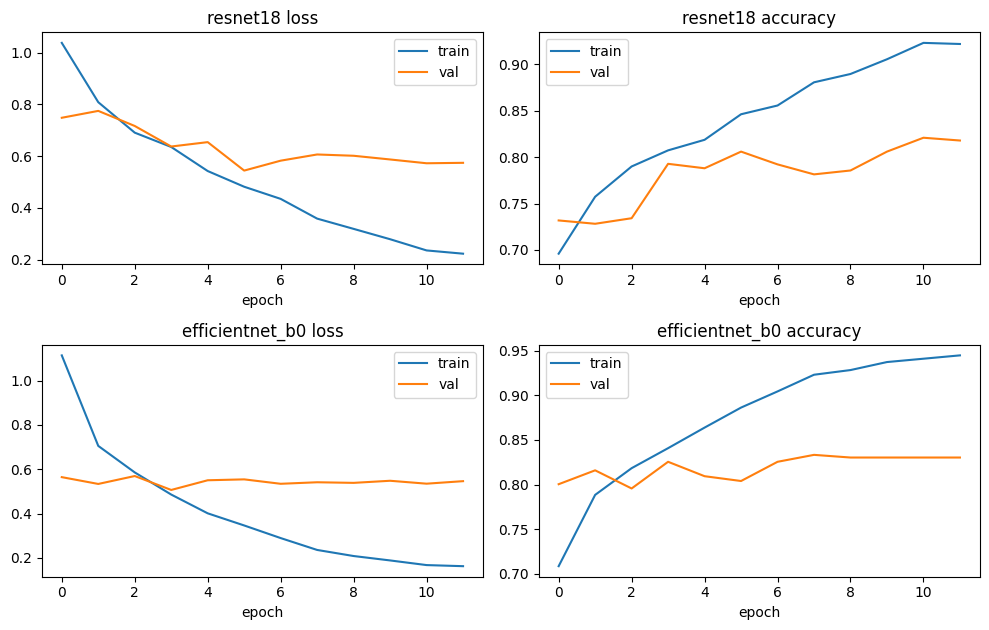

In [8]:
fig, ax = plt.subplots(len(results), 2, figsize=(10, 3.2*len(results)))
for r, (name, (H, _, _)) in enumerate(results.items()):
    ax[r,0].plot(H['tr_loss'], label='train'); ax[r,0].plot(H['va_loss'], label='val'); ax[r,0].set_title(f'{name} loss'); ax[r,0].legend()
    ax[r,1].plot(H['tr_acc'], label='train'); ax[r,1].plot(H['va_acc'], label='val'); ax[r,1].set_title(f'{name} accuracy'); ax[r,1].legend()
    for a in ax[r]: a.set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 6. Final test evaluation (run ONCE, on the best backbone chosen by validation macro F1)

Selected: resnet18
TEST  accuracy 0.82 | macro F1 0.68 | balanced acc 0.66

              precision    recall  f1-score   support

       akiec       0.63      0.41      0.50        41
         bcc       0.78      0.76      0.77        85
         bkl       0.71      0.66      0.68       184
          df       0.71      0.44      0.55        27
         mel       0.49      0.56      0.52       187
          nv       0.91      0.92      0.91      1104
        vasc       0.79      0.86      0.83        22

    accuracy                           0.82      1650
   macro avg       0.72      0.66      0.68      1650
weighted avg       0.82      0.82      0.82      1650



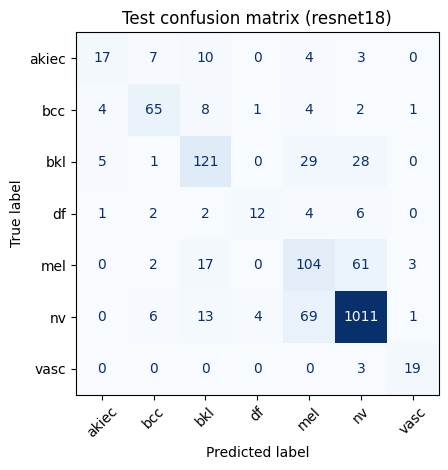

Melanoma recall (clinically most important): 0.56
Most confused pairs (true -> pred):
  nv -> mel: 69
  mel -> nv: 61
  bkl -> mel: 29
  bkl -> nv: 28
  mel -> bkl: 17
Training time (s): 604


In [9]:
best_name = max(results, key=lambda k: results[k][1]); print('Selected:', best_name)
model = build(best_name); model.load_state_dict(torch.load(f'{best_name}_best.pt'))
_, P, Y = evaluate(model, dl_te); pred = P.argmax(1)

acc = accuracy_score(Y, pred); mf1 = f1_score(Y, pred, average='macro'); bal = balanced_accuracy_score(Y, pred)
print(f'TEST  accuracy {acc:.2f} | macro F1 {mf1:.2f} | balanced acc {bal:.2f}\n')
print(classification_report(Y, pred, target_names=classes, digits=2))
cm = confusion_matrix(Y, pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title(f'Test confusion matrix ({best_name})'); plt.tight_layout(); plt.show()
mel = c2i['mel']; print(f'Melanoma recall (clinically most important): {cm[mel,mel]/cm[mel].sum():.2f}')
print('Most confused pairs (true -> pred):')
off = [(cm[i,j], classes[i], classes[j]) for i in range(7) for j in range(7) if i!=j]
for c, a, b in sorted(off, reverse=True)[:5]: print(f'  {a} -> {b}: {c}')
print('Training time (s):', round(results[best_name][2]))

## 7. Misclassified test images

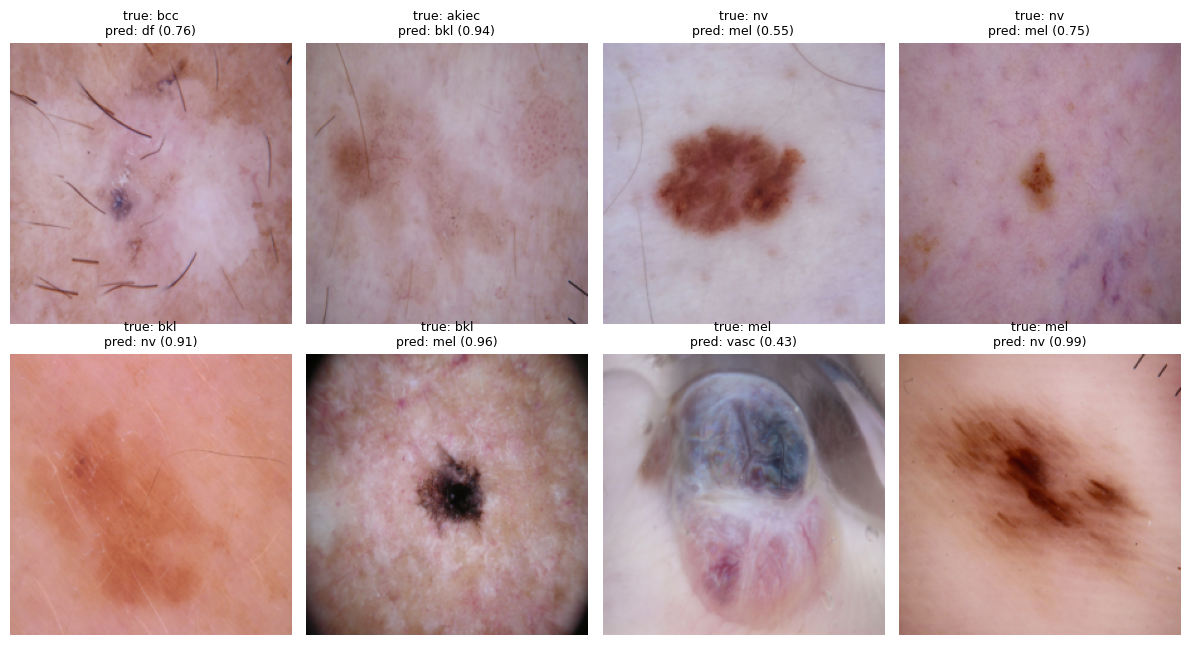

In [10]:
wrong = np.where(pred != Y)[0]
sel = np.random.RandomState(SEED).choice(wrong, 8, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(12, 6.5))
for a, k in zip(ax.ravel(), sel):
    a.imshow(IMGS[test_idx[k]]); a.axis('off')
    a.set_title(f'true: {classes[Y[k]]}\npred: {classes[pred[k]]} ({P[k].max():.2f})', fontsize=9)
plt.tight_layout(); plt.show()
# TODO (write in report): for each image give a reason, e.g. visually similar lesion type, hair/ruler/marker artefacts, low contrast, minority class.

## 8. Grad-CAM (does the model look at the lesion, not skin/ruler/borders?)

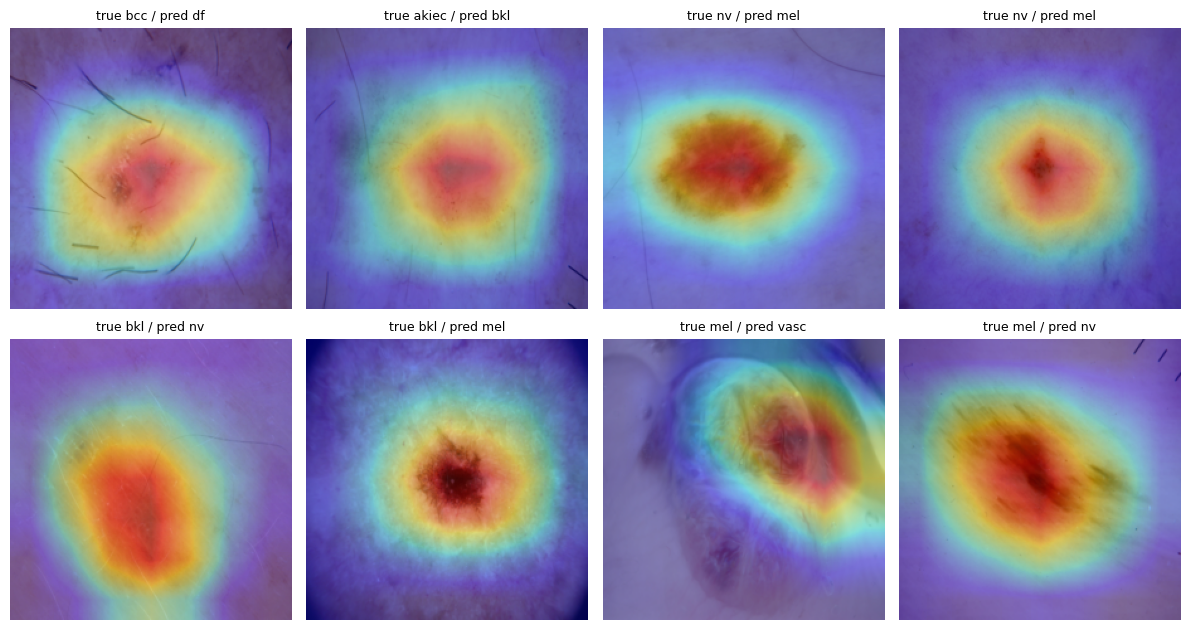

In [13]:
model = build(best_name); model.load_state_dict(torch.load(f'{best_name}_best.pt')); model.eval()

def gradcam(model, x, layer, cls):
    store = {}
    def fwd_hook(m, i, o):
        store['a'] = o
        o.register_hook(lambda g: store.__setitem__('g', g))
    h = layer.register_forward_hook(fwd_hook)
    try:
        model.zero_grad()
        out = model(x); out[0, cls].backward()
    finally:
        h.remove()
    w = store['g'].mean((2,3), keepdim=True)
    cam = torch.relu((w*store['a']).sum(1)).detach()[0]
    cam = (cam/(cam.max()+1e-8)).cpu().numpy()
    return np.array(Image.fromarray((cam*255).astype('uint8')).resize((IMG,IMG), Image.BILINEAR))/255.

layer = model.layer4[-1] if best_name=='resnet18' else model.features[-1]
fig, ax = plt.subplots(2, 4, figsize=(12, 6.5))
for a, k in zip(ax.ravel(), sel):
    x = eval_tf(IMGS[test_idx[k]]).unsqueeze(0).to(device)
    cam = gradcam(model, x, layer, int(pred[k]))
    a.imshow(IMGS[test_idx[k]]); a.imshow(cam, cmap='jet', alpha=0.4); a.axis('off')
    a.set_title(f'true {classes[Y[k]]} / pred {classes[pred[k]]}', fontsize=9)
plt.tight_layout(); plt.show()

## 9. Notes for the report (fill after running)
- **Dataset risks:** 67% nevi; same lesion has several images → split by `lesion_id` (verified, zero overlap).
- **Imbalance handling:** sqrt-inverse-frequency class-weighted loss; judged by macro F1 + balanced accuracy + melanoma recall.
- **Innovation:** backbone comparison on validation + Grad-CAM.
- **Limitations:** single dataset/European-Australian skin, mostly light skin types → bias; not a diagnostic tool.
- **Declare AI-assistant use** and cite: Tschandl et al., *The HAM10000 dataset*, Sci Data 2018.